<a href="https://colab.research.google.com/github/KKRavindu/EN4554-A02/blob/main/EN4554_A02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN4554 Assignment 2 — Convolutional Neural Networks

**Name:** Malshan K.K.R
**Index number:** 220379N
**GitHub repository:** _https://github.com/KKRavindu/EN4554-A02

---
**How to run.** In Colab: *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*.

* Set `QUICK = True` first. That runs every task on tiny subsets in about 10 minutes, so you can check that everything works.
* Then set `QUICK = False` for the real results (about 1.5–2 hours on a T4).
* Every experiment saves its results to Google Drive. If Colab disconnects, *Run all* again and finished experiments load from Drive instead of retraining.

In [1]:
# ===== Configuration =====
STUDENT_NAME = "Malshan K.K.R"
INDEX_NO     = "220379N"
GITHUB_URL   = "https://github.com/KKRavindu/EN4554-A02"

QUICK = True  # True = tiny smoke-test run (minutes). False = full assignment.
RERUN = False   # True = ignore results cached on Drive and retrain everything.
SEED  = 42

## 0. Setup: Google Drive, dataset, split and normalization

The dataset is stored once in Google Drive (`MyDrive/EN4554_A02/data`). The next cell looks for CIFAR-10 already on your Drive: the extracted `cifar-10-batches-py` folder or the `cifar-10-python.tar.gz` archive, in that folder or up to two levels inside *My Drive*. It downloads the dataset only if it finds neither. Each session it copies the data to the Colab machine's local disk, because reading from Drive during training is slow.

In [2]:
import os, sys, glob, shutil, json, time, math, copy, random, pickle, tarfile, warnings, contextlib
warnings.filterwarnings("ignore")

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/EN4554_A02'   # persistent: data, results, figures
    LOCAL_DATA  = '/content/data'                        # fast local copy used for training
else:                                                    # laptop / local Jupyter
    PROJECT_DIR = os.path.abspath('./EN4554_A02')
    LOCAL_DATA  = os.path.join(PROJECT_DIR, 'data')

DATA_DIR = os.path.join(PROJECT_DIR, 'data')
RES_DIR  = os.path.join(PROJECT_DIR, 'results_quick' if QUICK else 'results')
FIG_DIR  = os.path.join(PROJECT_DIR, 'figures_quick' if QUICK else 'figures')
for d in (DATA_DIR, RES_DIR, FIG_DIR, LOCAL_DATA):
    os.makedirs(d, exist_ok=True)
print('Project folder:', PROJECT_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/EN4554_A02


In [3]:
import torch, torchvision
BATCH_DIR = 'cifar-10-batches-py'

def find_existing_cifar():
    """Look for an extracted CIFAR-10 folder or the original .tar.gz archive."""
    roots = [DATA_DIR, PROJECT_DIR]
    if IN_COLAB:
        roots += ['/content/drive/MyDrive'] + glob.glob('/content/drive/MyDrive/*/') \
                 + glob.glob('/content/drive/MyDrive/*/*/')
    for r in roots:
        if os.path.isfile(os.path.join(r, BATCH_DIR, 'data_batch_1')):
            return 'folder', os.path.join(r, BATCH_DIR)
    for r in roots:
        tgz = os.path.join(r, 'cifar-10-python.tar.gz')
        if os.path.isfile(tgz):
            return 'tar', tgz
    return None, None

kind, path = find_existing_cifar()
if kind is None:
    print('CIFAR-10 not found on Drive -> downloading to', DATA_DIR)
    torchvision.datasets.CIFAR10(root=DATA_DIR, train=True, download=True)   # downloads + extracts once
    path = os.path.join(DATA_DIR, BATCH_DIR)
elif kind == 'tar':
    print('Found archive', path, '-> extracting to', DATA_DIR)
    with tarfile.open(path) as t:
        t.extractall(DATA_DIR)
    path = os.path.join(DATA_DIR, BATCH_DIR)
print('Dataset on Drive:', path)

local_path = os.path.join(LOCAL_DATA, BATCH_DIR)
if os.path.abspath(local_path) != os.path.abspath(path) and \
        not os.path.isfile(os.path.join(local_path, 'test_batch')):
    shutil.copytree(path, local_path, dirs_exist_ok=True)
print('Training reads from:', local_path, sorted(os.listdir(local_path)))

CIFAR-10 not found on Drive -> downloading to /content/drive/MyDrive/EN4554_A02/data


100%|██████████| 170M/170M [43:35<00:00, 65.2kB/s]


Dataset on Drive: /content/drive/MyDrive/EN4554_A02/data/cifar-10-batches-py
Training reads from: /content/data/cifar-10-batches-py ['batches.meta', 'data_batch_1', 'data_batch_2', 'data_batch_3', 'data_batch_4', 'data_batch_5', 'readme.html', 'test_batch']


In [4]:
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = device.type == 'cuda'     # mixed precision on the GPU (faster on a T4)
print('Device:', device, torch.cuda.get_device_name(0) if AMP else '')

def load_batch(file):
    with open(file, 'rb') as f:
        d = pickle.load(f, encoding='bytes')
    x = torch.from_numpy(np.asarray(d[b'data'], dtype=np.uint8).reshape(-1, 3, 32, 32))
    y = torch.tensor(d[b'labels'], dtype=torch.long)
    return x, y

parts = [load_batch(os.path.join(local_path, f'data_batch_{i}')) for i in range(1, 6)]
X_all = torch.cat([p[0] for p in parts]).float() / 255.
y_all = torch.cat([p[1] for p in parts])
X_test_raw, y_test = load_batch(os.path.join(local_path, 'test_batch'))
X_test_raw = X_test_raw.float() / 255.
CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# ---- 45k / 5k split with a fixed random permutation ----
perm = torch.randperm(50000, generator=torch.Generator().manual_seed(SEED))
tr_idx, va_idx = perm[:45000], perm[45000:]

# ---- per-channel mean / std from the 45k TRAINING images only ----
MEAN = X_all[tr_idx].mean(dim=(0, 2, 3)).view(1, 3, 1, 1)
STD  = X_all[tr_idx].std(dim=(0, 2, 3)).view(1, 3, 1, 1)
print('channel mean', MEAN.flatten().numpy().round(4), ' channel std', STD.flatten().numpy().round(4))
norm = lambda x: (x - MEAN) / STD

X_tr, y_tr = norm(X_all[tr_idx]).to(device), y_all[tr_idx].to(device)
X_va, y_va = norm(X_all[va_idx]).to(device), y_all[va_idx].to(device)
X_te, y_te = norm(X_test_raw).to(device), y_test.to(device)   # NOT used until the end of Task 4
del X_all, parts

if QUICK:   # tiny subsets, only to check that the code runs
    X_tr, y_tr, X_va, y_va = X_tr[:2048], y_tr[:2048], X_va[:1024], y_va[:1024]
print('train', tuple(X_tr.shape), ' val', tuple(X_va.shape), ' test', tuple(X_te.shape))
print('class counts in train split:', torch.bincount(y_tr.cpu(), minlength=10).tolist())

Device: cuda Tesla T4
channel mean [0.4917 0.4823 0.4467]  channel std [0.2471 0.2435 0.2616]
train (2048, 3, 32, 32)  val (1024, 3, 32, 32)  test (10000, 3, 32, 32)
class counts in train split: [211, 194, 206, 194, 204, 201, 211, 207, 219, 201]


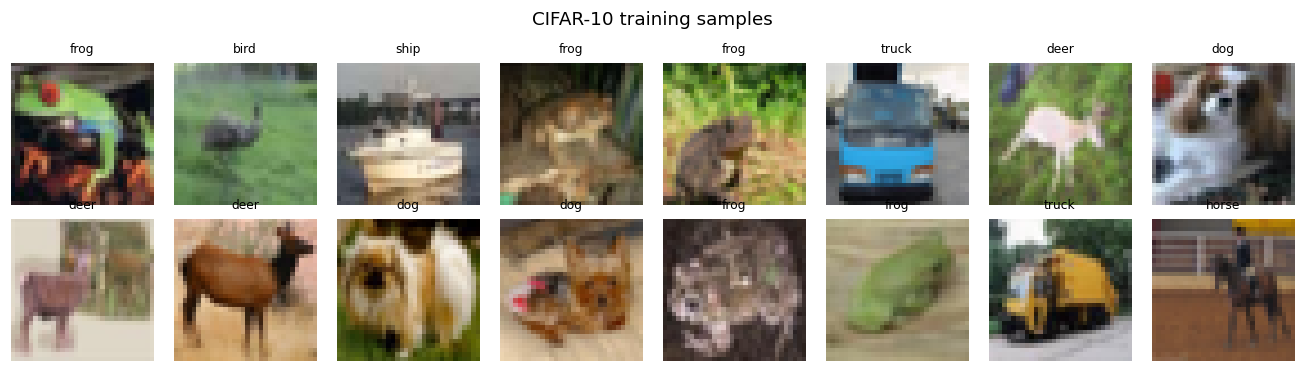

In [5]:
# a few training images (un-normalized for display)
fig, axs = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, i in zip(axs.flat, range(16)):
    img = (X_tr[i].cpu() * STD[0] + MEAN[0]).permute(1, 2, 0).clamp(0, 1)
    ax.imshow(img); ax.set_title(CLASSES[y_tr[i]], fontsize=8); ax.axis('off')
plt.suptitle('CIFAR-10 training samples'); plt.tight_layout(); plt.show()

### Shared utilities
The tensors already sit on the GPU, so a mini-batch is just an index into them. This is much faster than a `DataLoader`. Augmentations (flip+crop, cutout, mixup) are written by hand and run on the GPU on whole batches. `fit` is the training loop that Tasks 2–4 share. `cached` saves each experiment's history to Drive and reseeds before every experiment, so each result is reproducible on its own.

In [6]:
def autocast():
    return torch.autocast('cuda', dtype=torch.float16) if AMP else contextlib.nullcontext()

def make_scaler():
    try:
        return torch.amp.GradScaler('cuda', enabled=AMP)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=AMP)

def batches(X, y, bs, shuffle=True, gen=None):
    n = len(X)
    idx = torch.randperm(n, generator=gen).to(X.device) if shuffle else torch.arange(n, device=X.device)
    for k in range(0, n, bs):
        b = idx[k:k + bs]
        yield X[b], y[b]

# ---------------- augmentations (whole batch, on the GPU) ----------------
def flip_crop(x, pad=4):
    """Random horizontal flip + random 32x32 crop of the zero-padded (36x36) image."""
    n, c, h, w = x.shape
    flip = torch.rand(n, device=x.device) < 0.5
    x = torch.where(flip.view(n, 1, 1, 1), x.flip(3), x)
    xp = F.pad(x, (pad, pad, pad, pad))
    i = torch.randint(0, 2 * pad + 1, (n,), device=x.device)    # per-image vertical offset
    j = torch.randint(0, 2 * pad + 1, (n,), device=x.device)    # per-image horizontal offset
    rows = (i.view(n, 1) + torch.arange(h, device=x.device)).view(n, 1, h, 1).expand(n, c, h, w + 2 * pad)
    xp = xp.gather(2, rows)
    cols = (j.view(n, 1) + torch.arange(w, device=x.device)).view(n, 1, 1, w).expand(n, c, h, w)
    return xp.gather(3, cols)

def cutout(x, size=16):
    """Zero a random size x size square per image (DeVries & Taylor, 2017). Centre may be near the border."""
    n, c, h, w = x.shape
    cy = torch.randint(0, h, (n, 1, 1), device=x.device) - size // 2
    cx = torch.randint(0, w, (n, 1, 1), device=x.device) - size // 2
    ys = torch.arange(h, device=x.device).view(1, h, 1)
    xs = torch.arange(w, device=x.device).view(1, 1, w)
    hole = (ys >= cy) & (ys < cy + size) & (xs >= cx) & (xs < cx + size)       # (n, h, w)
    return x * (~hole).unsqueeze(1).to(x.dtype)

def mixup(x, y, alpha):
    """Convex combination of pairs of images; the loss mixes the two labels with the same lambda."""
    lam = float(np.random.beta(alpha, alpha))
    idx = torch.randperm(x.size(0), device=x.device)
    return lam * x + (1 - lam) * x[idx], y, y[idx], lam

def make_aug(flipcrop=False, cutout_size=0):
    if not flipcrop and not cutout_size:
        return None
    def aug(x):
        if flipcrop:    x = flip_crop(x)
        if cutout_size: x = cutout(x, cutout_size)
        return x
    return aug

# ---------------- evaluation and training ----------------
@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    model.eval(); correct, loss = 0, 0.
    for xb, yb in batches(X, y, bs, shuffle=False):
        with autocast():
            out = model(xb)
        loss += F.cross_entropy(out.float(), yb, reduction='sum').item()
        correct += (out.argmax(1) == yb).sum().item()
    return correct / len(X), loss / len(X)

def fit(model, opt, X, y, epochs, bs=128, aug=None, mixup_alpha=0., label_smoothing=0.,
        sched=None, eval_train=False, name=''):
    """Generic training loop. Returns per-epoch / per-iteration history."""
    hist = dict(train_loss=[], train_acc=[], val_acc=[], val_loss=[], iter_loss=[], lr=[])
    scaler, gen, t0 = make_scaler(), torch.Generator().manual_seed(SEED), time.time()
    for ep in range(epochs):
        model.train(); losses = []
        for xb, yb in batches(X, y, bs, True, gen):
            if aug is not None:
                xb = aug(xb)
            with autocast():
                if mixup_alpha > 0:
                    xb, ya, yb2, lam = mixup(xb, yb, mixup_alpha)
                    out = model(xb)
                    loss = lam * F.cross_entropy(out, ya, label_smoothing=label_smoothing) + \
                           (1 - lam) * F.cross_entropy(out, yb2, label_smoothing=label_smoothing)
                else:
                    loss = F.cross_entropy(model(xb), yb, label_smoothing=label_smoothing)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            if sched is not None:
                sched.step()
            losses.append(loss.detach())
        ep_losses = torch.stack(losses).float().cpu()
        hist['iter_loss'] += ep_losses.tolist()
        tl = ep_losses.mean().item()
        va, vl = evaluate(model, X_va, y_va)
        hist['train_loss'].append(tl); hist['val_acc'].append(va); hist['val_loss'].append(vl)
        hist['lr'].append(opt.param_groups[0]['lr'])
        if eval_train:   # accuracy on the CLEAN training images, in eval mode
            hist['train_acc'].append(evaluate(model, X, y)[0])
        if not math.isfinite(tl):
            print(f'  {name}: loss is not finite at epoch {ep+1} -> diverged, stopping')
            hist['diverged'] = True
            break
        if (ep + 1) % max(1, epochs // 5) == 0 or ep == epochs - 1:
            msg = f'  {name:28s} ep {ep+1:3d}/{epochs}  loss {tl:.4f}  val_acc {va:.4f}'
            if eval_train:
                msg += f'  train_acc {hist["train_acc"][-1]:.4f}'
            print(msg + f'  [{time.time() - t0:.0f}s]')
    hist['time'] = time.time() - t0
    return hist

# ---------------- bookkeeping ----------------
def cached(name, fn):
    """Run fn() once and save its JSON-able result on Drive; afterwards just load it."""
    path = os.path.join(RES_DIR, name + '.json')
    if os.path.exists(path) and not RERUN:
        with open(path) as f:
            print(f'[loaded from Drive] {name}')
            return json.load(f)
    set_seed()
    out = fn()
    with open(path, 'w') as f:
        json.dump(out, f)
    return out

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name + '.png'), dpi=150, bbox_inches='tight')

def n_params(m):
    return sum(p.numel() for p in m.parameters())

def E(full, quick):           # number of epochs: full run vs quick smoke test
    return quick if QUICK else full

def smooth(v, k=50):
    v = np.asarray(v, dtype=float)
    k = max(1, min(k, len(v)))
    return np.convolve(v, np.ones(k) / k, mode='valid')

---
# Task 1: Backpropagation

## 1(a) Layers with explicit forward/backward and an MLP

No autograd is used here. Each layer stores what it needs during `forward` and returns $\partial L/\partial(\text{input})$ in `backward`.

* **Linear** $y = xW + b$: $\;\partial L/\partial W = x^\top g$, $\;\partial L/\partial b = \sum_n g_n$, $\;\partial L/\partial x = g W^\top$.
* **ReLU**: $\partial L/\partial x = g \odot \mathbb{1}[x>0]$. **Sigmoid** (for 1(d)): $\partial L/\partial x = g\odot\sigma(x)(1-\sigma(x))$.
* **Softmax cross-entropy** (combined for numerical stability): $L = -\frac1N\sum_n \log p_{n,y_n}$ with $p=\mathrm{softmax}(z)$. The gradient is $\partial L/\partial z = (p - \text{onehot}(y))/N$. Subtracting the row maximum before the exponential avoids overflow.

In [7]:
class Linear:
    """y = x @ W + b. Caches x for the backward pass."""
    def __init__(self, n_in, n_out, init='kaiming', dtype=torch.float32, dev='cpu'):
        std = math.sqrt(2.0 / n_in) if init == 'kaiming' else math.sqrt(2.0 / (n_in + n_out))  # Kaiming / Xavier
        self.W = (torch.randn(n_in, n_out, dtype=dtype) * std).to(dev)
        self.b = torch.zeros(n_out, dtype=dtype, device=dev)
    def forward(self, x):
        self.x = x
        return x @ self.W + self.b
    def backward(self, g):              # g = dL/dy, shape (N, n_out)
        self.dW = self.x.t() @ g        # (n_in, n_out)
        self.db = g.sum(0)              # (n_out,)
        return g @ self.W.t()           # dL/dx, shape (N, n_in)
    def params(self): return [self.W, self.b]
    def grads(self):  return [self.dW, self.db]

class ReLU:
    def forward(self, x):
        self.mask = (x > 0).to(x.dtype)
        return x * self.mask
    def backward(self, g): return g * self.mask
    def params(self): return []
    def grads(self):  return []

class Sigmoid:
    def forward(self, x):
        self.s = 1.0 / (1.0 + torch.exp(-x))
        return self.s
    def backward(self, g): return g * self.s * (1.0 - self.s)
    def params(self): return []
    def grads(self):  return []

class SoftmaxCrossEntropy:
    """Mean cross-entropy of softmax(logits); gradient w.r.t. logits is (p - onehot) / N."""
    def forward(self, logits, y):
        z = logits - logits.max(dim=1, keepdim=True).values            # numerical stability
        logp = z - torch.log(torch.exp(z).sum(dim=1, keepdim=True))
        self.p, self.y = torch.exp(logp), y
        return -logp[torch.arange(len(y), device=y.device), y].mean()
    def backward(self):
        g = self.p.clone()
        g[torch.arange(len(self.y), device=self.y.device), self.y] -= 1.0
        return g / len(self.y)

class MLP:
    def __init__(self, sizes, act='relu', init=None, dtype=torch.float32, dev='cpu'):
        init = init or ('kaiming' if act == 'relu' else 'xavier')
        Act = ReLU if act == 'relu' else Sigmoid
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], init, dtype, dev))
            if i < len(sizes) - 2:
                self.layers.append(Act())
        self.loss_fn = SoftmaxCrossEntropy()
    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x
    def loss(self, x, y):
        return self.loss_fn.forward(self.forward(x), y)
    def backward(self):
        g = self.loss_fn.backward()
        for layer in reversed(self.layers):
            g = layer.backward(g)
    def params(self):  return [p for l in self.layers for p in l.params()]
    def grads(self):   return [g for l in self.layers for g in l.grads()]
    def linears(self): return [l for l in self.layers if isinstance(l, Linear)]

## 1(b) Gradient check against autograd and centred finite differences

The same weights are copied into an ordinary PyTorch graph (`torch.relu`, `F.cross_entropy`) and differentiated with autograd. Each entry is also checked with centred finite differences, $\frac{L(\theta+h)-L(\theta-h)}{2h}$ with $h=10^{-6}$, in float64. The relative error is $\|g_{\text{ours}}-g_{\text{ref}}\|/(\|g_{\text{ours}}\|+\|g_{\text{ref}}\|)$. Two networks are checked:
1. a small network (20-16-16-5) on random data, where **every** parameter is checked by finite differences, with ReLU and with sigmoid;
2. a CIFAR-sized network (3072-128-64-10) on a real batch, checked fully against autograd and on 40 random entries per tensor by finite differences.

In [8]:
def autograd_grads(mlp, x, y, act='relu'):
    """Same network and weights, built from torch ops and differentiated by autograd."""
    ps = [p.clone().requires_grad_(True) for p in mlp.params()]
    h = x
    for k in range(0, len(ps), 2):
        h = h @ ps[k] + ps[k + 1]
        if k < len(ps) - 2:
            h = torch.relu(h) if act == 'relu' else torch.sigmoid(h)
    loss = F.cross_entropy(h, y)
    loss.backward()
    return loss.detach(), [p.grad for p in ps]

def fd_grad(mlp, x, y, p, idx, h=1e-6):
    old = p[idx].item()
    p[idx] = old + h; lp = mlp.loss(x, y).item()
    p[idx] = old - h; lm = mlp.loss(x, y).item()
    p[idx] = old
    return (lp - lm) / (2 * h)

def rel_err(a, b):
    return ((a - b).norm() / (a.norm() + b.norm()).clamp_min(1e-30)).item()

def grad_check(sizes, x, y, act='relu', n_fd=None):
    torch.manual_seed(SEED)
    mlp = MLP(sizes, act=act, dtype=torch.float64)
    loss = mlp.loss(x, y); mlp.backward()
    ours = [g.clone() for g in mlp.grads()]
    ag_loss, ag = autograd_grads(mlp, x, y, act)
    names = [f'{t}{i + 1}' for i in range(len(sizes) - 1) for t in ('W', 'b')]
    rows = []
    for name, p, g, ga in zip(names, mlp.params(), ours, ag):
        flat = torch.arange(p.numel()) if n_fd is None else torch.randperm(p.numel())[:n_fd]
        fd = torch.tensor([fd_grad(mlp, x, y, p, tuple(int(k) for k in np.unravel_index(int(i), tuple(p.shape))))
                           for i in flat], dtype=torch.float64)
        g_sub = g.reshape(-1)[flat]
        rows.append({'param': name, 'shape': tuple(p.shape),
                     'rel.err vs autograd': rel_err(g, ga),
                     'allclose autograd': torch.allclose(g, ga, rtol=1e-6, atol=1e-10),
                     '#FD entries': len(flat),
                     'rel.err vs FD': rel_err(g_sub, fd),
                     'allclose FD': torch.allclose(g_sub, fd, rtol=1e-4, atol=1e-7)})
    print(f'{act:7s} {str(sizes):22s} loss ours = {loss.item():.12f} | autograd = {ag_loss.item():.12f}')
    return pd.DataFrame(rows)

torch.manual_seed(0)
xs, ys = torch.randn(8, 20, dtype=torch.float64), torch.randint(0, 5, (8,))
xc, yc = X_tr[:64].reshape(64, -1).double().cpu(), y_tr[:64].cpu()

checks = {'small, ReLU':    grad_check([20, 16, 16, 5], xs, ys, 'relu'),
          'small, sigmoid': grad_check([20, 16, 16, 5], xs, ys, 'sigmoid'),
          'CIFAR, ReLU':    grad_check([3072, 128, 64, 10], xc, yc, 'relu', n_fd=40)}
for k, df in checks.items():
    print(f'\n=== {k} ===')
    display(df)
ok = all(df['allclose autograd'].all() and df['allclose FD'].all() for df in checks.values())
print('\nAll gradients match (torch.allclose):', ok)

relu    [20, 16, 16, 5]        loss ours = 2.542914187408 | autograd = 2.542914187408
sigmoid [20, 16, 16, 5]        loss ours = 1.764153286574 | autograd = 1.764153286574
relu    [3072, 128, 64, 10]    loss ours = 2.705861652728 | autograd = 2.705861652728

=== small, ReLU ===


,param,shape,rel.err vs autograd,allclose autograd,#FD entries,rel.err vs FD,allclose FD
0,W1,"(20, 16)",1.0152e-16,True,320,5.5695e-10,True
1,b1,"(16,)",1.0020e-16,True,16,6.1708e-10,True
2,W2,"(16, 16)",5.3165e-17,True,256,5.1670e-10,True
3,b2,"(16,)",4.3274e-17,True,16,3.1303e-10,True
4,W3,"(16, 5)",3.4086e-17,True,80,3.4205e-10,True
5,b3,"(5,)",2.5504e-17,True,5,1.6505e-10,True



=== small, sigmoid ===


,param,shape,rel.err vs autograd,allclose autograd,#FD entries,rel.err vs FD,allclose FD
0,W1,"(20, 16)",1.2887e-16,True,320,9.6388e-09,True
1,b1,"(16,)",8.9679e-17,True,16,5.7972e-09,True
2,W2,"(16, 16)",7.2547e-17,True,256,2.5725e-09,True
3,b2,"(16,)",7.3850e-17,True,16,1.0435e-09,True
4,W3,"(16, 5)",5.3196e-17,True,80,4.1100e-10,True
5,b3,"(5,)",6.6287e-17,True,5,9.4393e-11,True



=== CIFAR, ReLU ===


,param,shape,rel.err vs autograd,allclose autograd,#FD entries,rel.err vs FD,allclose FD
0,W1,"(3072, 128)",1.1322e-16,True,40,1.0022e-08,True
1,b1,"(128,)",9.5370e-17,True,40,4.8234e-09,True
2,W2,"(128, 64)",7.9738e-17,True,40,3.3145e-09,True
3,b2,"(64,)",7.1376e-17,True,40,5.0609e-09,True
4,W3,"(64, 10)",6.3882e-17,True,40,1.9849e-09,True
5,b3,"(10,)",7.2226e-17,True,10,9.0498e-10,True



All gradients match (torch.allclose): True


**Interpretation.** The hand-written backward pass agrees with autograd to about $10^{-15}$–$10^{-16}$ relative error, which is float64 round-off. Both compute the same chain rule, so they differ only in the order of floating-point operations. Against centred finite differences the errors are larger, typically $10^{-8}$–$10^{-10}$. That is expected: finite differences carry an $O(h^2)$ truncation error plus cancellation error of order $\varepsilon_{\text{mach}}/h$, and a ReLU kink may lie inside $[\theta-h,\theta+h]$. The usual rule of thumb is that a relative error below about $10^{-7}$ means the gradient is correct. `torch.allclose` returns `True` for every parameter tensor, so the backward pass of every layer is correct. *(✏️ Check these orders of magnitude against your printed tables.)*

## 1(c) Training the MLP with SGD on flattened CIFAR-10

Architecture 3072 → 512 → 256 → 10 with ReLU and Kaiming initialization. Training uses plain mini-batch SGD written by hand (`p -= lr * g`), batch size 128, learning rate 0.05 with cosine decay, for 20 epochs. Autograd is not used anywhere.

epoch  1  train loss 2.2547  val loss 1.9635  val acc 0.3135  [0s]
epoch  2  train loss 1.5018  val loss 1.9050  val acc 0.3379  [0s]


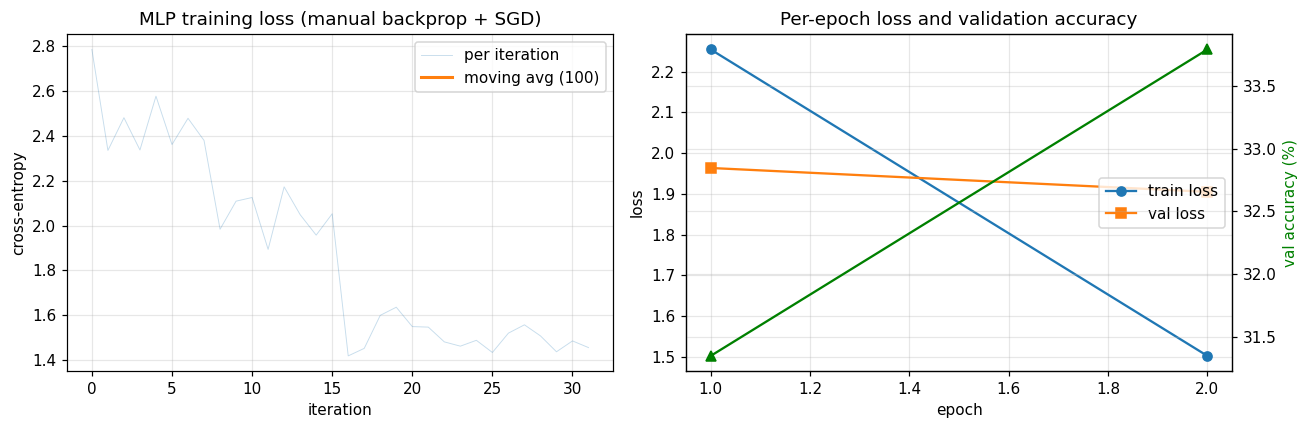

Final validation accuracy: 33.79%   (best 33.79%)


In [9]:
def train_manual_mlp():
    mlp = MLP([3072, 512, 256, 10], act='relu', dev=device)
    epochs, bs, lr0 = E(20, 2), 128, 0.05
    Xf_tr, Xf_va = X_tr.reshape(len(X_tr), -1), X_va.reshape(len(X_va), -1)
    gen = torch.Generator().manual_seed(SEED)
    hist = dict(iter_loss=[], train_loss=[], val_acc=[], val_loss=[])
    step, total = 0, epochs * math.ceil(len(Xf_tr) / bs)
    t0 = time.time()
    for ep in range(epochs):
        losses = []
        for xb, yb in batches(Xf_tr, y_tr, bs, True, gen):
            lr = 0.5 * lr0 * (1 + math.cos(math.pi * step / total))     # cosine decay
            loss = mlp.loss(xb, yb)
            mlp.backward()
            for p, g in zip(mlp.params(), mlp.grads()):
                p -= lr * g                                              # SGD update (in place)
            losses.append(loss); step += 1
        losses = torch.stack(losses).float().cpu()
        hist['iter_loss'] += losses.tolist(); hist['train_loss'].append(losses.mean().item())
        correct, vl = 0, 0.
        for xb, yb in batches(Xf_va, y_va, 1000, shuffle=False):
            logits = mlp.forward(xb)
            vl += mlp.loss_fn.forward(logits, yb).item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
        hist['val_acc'].append(correct / len(Xf_va)); hist['val_loss'].append(vl / len(Xf_va))
        print(f'epoch {ep+1:2d}  train loss {hist["train_loss"][-1]:.4f}  val loss {hist["val_loss"][-1]:.4f}'
              f'  val acc {hist["val_acc"][-1]:.4f}  [{time.time()-t0:.0f}s]')
    return hist

h1c = cached('t1c_mlp', train_manual_mlp)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
it = np.arange(len(h1c['iter_loss']))
ax[0].plot(it, h1c['iter_loss'], alpha=0.25, lw=0.6, label='per iteration')
ax[0].plot(it[len(it) - len(smooth(h1c['iter_loss'], 100)):], smooth(h1c['iter_loss'], 100), lw=2, label='moving avg (100)')
ax[0].set(xlabel='iteration', ylabel='cross-entropy', title='MLP training loss (manual backprop + SGD)'); ax[0].legend()
ep = np.arange(1, len(h1c['val_acc']) + 1)
ax[1].plot(ep, h1c['train_loss'], 'o-', label='train loss')
ax[1].plot(ep, h1c['val_loss'], 's-', label='val loss')
ax2 = ax[1].twinx(); ax2.plot(ep, np.array(h1c['val_acc']) * 100, 'g^-', label='val acc'); ax2.set_ylabel('val accuracy (%)', color='g')
ax[1].set(xlabel='epoch', ylabel='loss', title='Per-epoch loss and validation accuracy'); ax[1].legend(loc='center right')
plt.tight_layout(); savefig('t1c_mlp'); plt.show()
print(f"Final validation accuracy: {h1c['val_acc'][-1]*100:.2f}%   (best {max(h1c['val_acc'])*100:.2f}%)")

**Interpretation.** The training loss falls quickly in the first few epochs and keeps falling as the cosine schedule shrinks the step size. The per-iteration curve is noisy because each step uses only 128 images. Validation accuracy levels off at about **[XX] %** (an MLP on raw pixels usually reaches 50–56 %), far above the 10 % of chance. Validation loss stops improving, and may start to rise, while training loss keeps falling, so the MLP begins to overfit. An MLP has no notion of spatial locality or translation invariance. It has to learn a separate weight for every pixel position and has about 1.7 M parameters, which is why it generalizes much worse than the small CNNs in Tasks 2–4.

## 1(d) Per-layer gradient norms at initialization: 10-layer MLP, sigmoid vs ReLU

Network 3072 → 256 (×9) → 10, so 10 Linear layers. Each activation uses its usual initialization: Kaiming for ReLU, Xavier for sigmoid. A sigmoid network with Kaiming initialization is also shown, to separate the effect of the activation from the effect of the initialization. The plot shows $\|\partial L/\partial W_\ell\|_F$ for one batch of 512 images, as the mean over 5 random initializations (band = min–max).

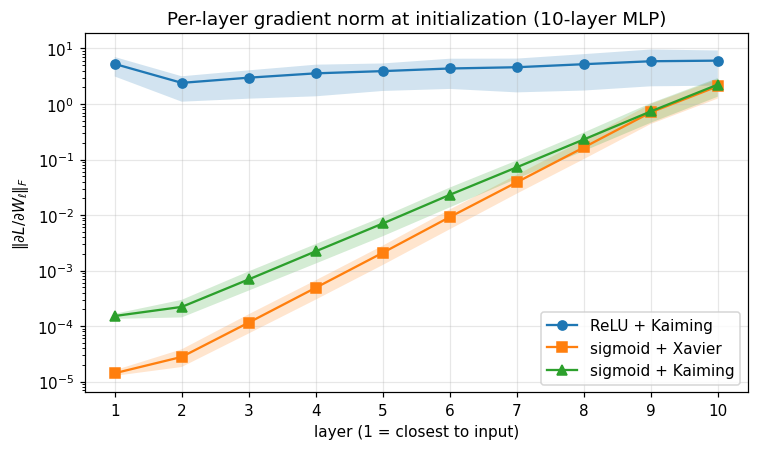

,layer 1,layer 2,layer 3,layer 4,layer 5,layer 6,layer 7,layer 8,layer 9,layer 10
ReLU + Kaiming,5.2677e+00,2.4023e+00,2.9797,3.5662,3.9117,4.3618,4.5946,5.2124,5.8900,6.0399
sigmoid + Xavier,1.4142e-05,2.7811e-05,0.0001,0.0005,0.0021,0.0092,0.0390,0.1651,0.7078,2.0895
sigmoid + Kaiming,1.5166e-04,2.2132e-04,0.0007,0.0022,0.0070,0.0231,0.0725,0.2298,0.7357,2.2396


ReLU + Kaiming    : |grad| layer10 / layer1 = 1.15
sigmoid + Xavier  : |grad| layer10 / layer1 = 1.48e+05
sigmoid + Kaiming : |grad| layer10 / layer1 = 1.48e+04


In [10]:
def layer_grad_norms(act, init, n_seeds=5, n=512):
    xb, yb = X_tr[:n].reshape(n, -1).float(), y_tr[:n]
    out = []
    for s in range(n_seeds):
        torch.manual_seed(s)
        mlp = MLP([3072] + [256] * 9 + [10], act=act, init=init, dev=device)
        mlp.loss(xb, yb); mlp.backward()
        out.append([l.dW.norm().item() for l in mlp.linears()])
    return np.array(out)

cfg1d = {'ReLU + Kaiming': ('relu', 'kaiming'), 'sigmoid + Xavier': ('sigmoid', 'xavier'),
         'sigmoid + Kaiming': ('sigmoid', 'kaiming')}
gn = {k: layer_grad_norms(*v) for k, v in cfg1d.items()}

plt.figure(figsize=(7, 4.2))
layers = np.arange(1, 11)
for (k, v), mk in zip(gn.items(), ['o', 's', '^']):
    plt.semilogy(layers, v.mean(0), marker=mk, label=k)
    plt.fill_between(layers, v.min(0), v.max(0), alpha=0.2)
plt.xticks(layers); plt.xlabel('layer (1 = closest to input)'); plt.ylabel(r'$\|\partial L/\partial W_\ell\|_F$')
plt.title('Per-layer gradient norm at initialization (10-layer MLP)'); plt.legend()
plt.tight_layout(); savefig('t1d_gradnorms'); plt.show()

display(pd.DataFrame({k: v.mean(0) for k, v in gn.items()}, index=[f'layer {i}' for i in layers]).T)
for k, v in gn.items():
    print(f'{k:18s}: |grad| layer10 / layer1 = {v.mean(0)[-1] / v.mean(0)[0]:.3g}')

**Interpretation.** Going backwards from layer $\ell+1$ to layer $\ell$, the gradient is multiplied by $W^\top$ and by the activation's derivative: $\delta_\ell = (W_{\ell+1}^\top \delta_{\ell+1}) \odot f'(z_\ell)$.

* **Sigmoid:** $\sigma'(z) \le 0.25$, and it is close to 0.25 only near $z=0$. Every layer therefore shrinks the gradient by roughly a factor of 4 or more, so it decays geometrically toward the input. The plot shows the gradient norm at layer 1 several orders of magnitude below that at layer 10 (**[ratio]**). This is the **vanishing-gradient** problem: the early layers barely learn. Kaiming initialization doesn't fix it (green curve), because the cause is the activation's small derivative, not the scale of the weights.
* **ReLU + Kaiming:** $\mathrm{ReLU}'$ is 1 for active units and 0 otherwise, so about half the units pass the gradient through unchanged. Kaiming's variance $2/n_{\text{in}}$ is chosen exactly to make up for the half that are switched off. The variance of the signal, and of the gradient, stays roughly constant from layer to layer, so the curve is nearly flat and every layer receives a usable gradient.

This is why ReLU-type activations with variance-preserving initialization (and later, batch norm and residual connections) made deep networks trainable.

---
# Task 2: Optimizers

## 2(a) SGD with momentum and Adam as `torch.optim.Optimizer` subclasses

* **SGD + momentum** (PyTorch convention, no dampening): $g \leftarrow g + \lambda\theta$; $\;b_t = \mu b_{t-1} + g$ (with $b_1 = g$); $\;\theta \leftarrow \theta - \eta\, b_t$.
* **Adam**: $m_t = \beta_1 m_{t-1} + (1-\beta_1)g$, $\;v_t = \beta_2 v_{t-1} + (1-\beta_2)g^2$. The bias corrections $\hat m_t = m_t/(1-\beta_1^t)$ and $\hat v_t = v_t/(1-\beta_2^t)$ are needed because $m_0=v_0=0$ pulls both averages toward 0 in the first steps. The update is $\theta \leftarrow \theta - \eta\, \hat m_t / (\sqrt{\hat v_t}+\epsilon)$.

In [11]:
class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-2, momentum=0.0, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, mu, wd = group['lr'], group['momentum'], group['weight_decay']
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    g = g.add(p, alpha=wd)                       # L2 penalty gradient
                if mu != 0:
                    state = self.state[p]
                    if 'buf' not in state:
                        state['buf'] = g.clone()                 # b_1 = g_1
                    else:
                        state['buf'].mul_(mu).add_(g)            # b_t = mu b_{t-1} + g_t
                    g = state['buf']
                p.add_(g, alpha=-lr)
        return loss

class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            b1, b2 = group['betas']
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                if group['weight_decay'] != 0:
                    g = g.add(p, alpha=group['weight_decay'])
                st = self.state[p]
                if len(st) == 0:
                    st['step'] = 0
                    st['m'] = torch.zeros_like(p)
                    st['v'] = torch.zeros_like(p)
                st['step'] += 1
                t = st['step']
                st['m'].mul_(b1).add_(g, alpha=1 - b1)            # first moment
                st['v'].mul_(b2).addcmul_(g, g, value=1 - b2)     # second moment
                m_hat = st['m'] / (1 - b1 ** t)                   # bias correction
                v_hat = st['v'] / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(group['eps']), value=-group['lr'])
        return loss

,max |θ_mine − θ_torch| after 200 steps,torch.allclose
SGD (lr=0.05),0.0,True
"SGD+momentum (0.9, wd=5e-4)",0.0,True
Adam (lr=1e-3),0.0,True
"Adam (lr=1e-3, wd=1e-4)",0.0,True


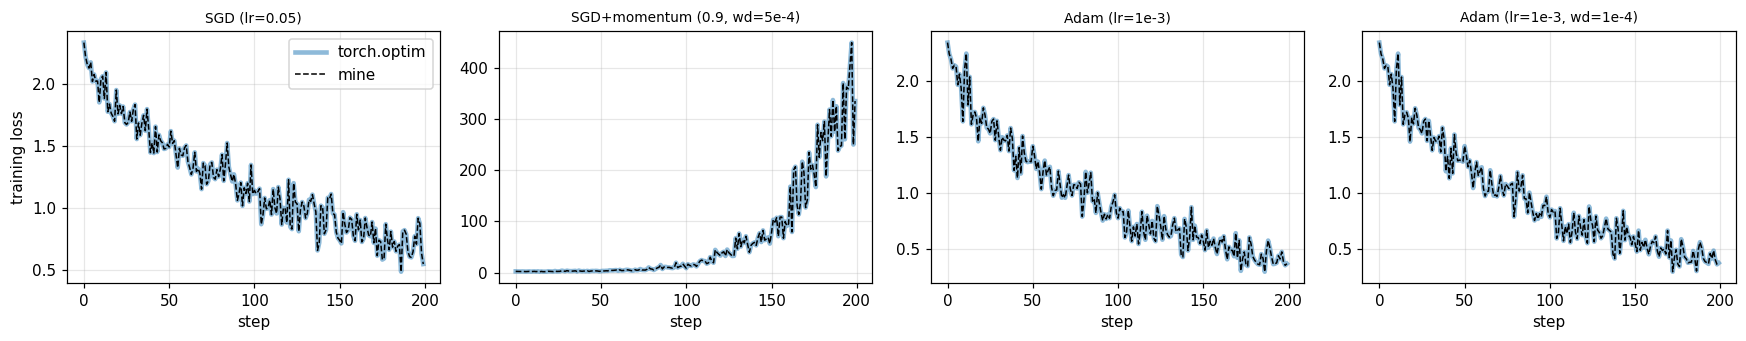

In [12]:
def compare_optimizers(make_mine, make_ref, steps=200):
    """Train two identical float64 nets on the same mini-batches, one with each optimizer."""
    torch.manual_seed(0)
    net = nn.Sequential(nn.Flatten(), nn.Linear(3072, 64), nn.ReLU(), nn.Linear(64, 10)).double()
    net_ref = copy.deepcopy(net)
    opt, opt_ref = make_mine(net.parameters()), make_ref(net_ref.parameters())
    xs, ys = X_tr[:1024].double().cpu(), y_tr[:1024].cpu()
    L, L_ref = [], []
    for s in range(steps):
        idx = torch.randint(0, len(xs), (64,))
        for m, o, rec in ((net, opt, L), (net_ref, opt_ref, L_ref)):
            o.zero_grad()
            loss = F.cross_entropy(m(xs[idx]), ys[idx])
            loss.backward(); o.step(); rec.append(loss.item())
    pairs = list(zip(net.parameters(), net_ref.parameters()))
    return dict(max_abs_diff=max((p - q).abs().max().item() for p, q in pairs),
                allclose=all(torch.allclose(p, q, rtol=1e-7, atol=1e-10) for p, q in pairs),
                losses=L, losses_ref=L_ref)

tests = {
  'SGD (lr=0.05)':                    (lambda p: MySGD(p, lr=0.05),
                                       lambda p: torch.optim.SGD(p, lr=0.05)),
  'SGD+momentum (0.9, wd=5e-4)':      (lambda p: MySGD(p, lr=0.05, momentum=0.9, weight_decay=5e-4),
                                       lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9, weight_decay=5e-4)),
  'Adam (lr=1e-3)':                   (lambda p: MyAdam(p, lr=1e-3),
                                       lambda p: torch.optim.Adam(p, lr=1e-3)),
  'Adam (lr=1e-3, wd=1e-4)':          (lambda p: MyAdam(p, lr=1e-3, weight_decay=1e-4),
                                       lambda p: torch.optim.Adam(p, lr=1e-3, weight_decay=1e-4)),
}
res2a = {k: compare_optimizers(*v) for k, v in tests.items()}
display(pd.DataFrame({k: {'max |θ_mine − θ_torch| after 200 steps': v['max_abs_diff'],
                          'torch.allclose': v['allclose']} for k, v in res2a.items()}).T)

fig, axs = plt.subplots(1, len(res2a), figsize=(16, 3.2))
for ax, (k, v) in zip(axs, res2a.items()):
    ax.plot(v['losses_ref'], lw=3, alpha=0.5, label='torch.optim')
    ax.plot(v['losses'], 'k--', lw=1, label='mine')
    ax.set_title(k, fontsize=9); ax.set_xlabel('step')
axs[0].set_ylabel('training loss'); axs[0].legend()
plt.tight_layout(); savefig('t2a_match'); plt.show()

**Interpretation.** After 200 identical steps on identical mini-batches, the parameters from my optimizers and from PyTorch's differ only at float64 round-off (about $10^{-15}$), and `torch.allclose` is `True` in every case, including with weight decay. The loss curves lie on top of each other. PyTorch's Adam computes $\frac{\eta}{1-\beta_1^t}\, m_t / (\sqrt{v_t}/\sqrt{1-\beta_2^t}+\epsilon)$, which is algebraically the same as my $\eta\,\hat m_t/(\sqrt{\hat v_t}+\epsilon)$, so only the order of floating-point operations differs.

## 2(b) Trajectories on $f(x,y)=\tfrac12(x^2+50y^2)$

The Hessian is $\mathrm{diag}(1, 50)$, so the condition number is $\kappa = 50$: the valley is 50 times steeper across $y$ than along $x$. Gradient descent is stable only for $\eta < 2/50 = 0.04$. All three start at $(-9, 1.8)$ and take 100 steps. The optimizers are the ones from 2(a), acting on a 2-element tensor. Learning rates: SGD $\eta=0.035$ (close to the stability limit), SGD with momentum the same $\eta=0.035$ with $\mu=0.9$ (so momentum is the only change), and Adam $\eta=0.3$.

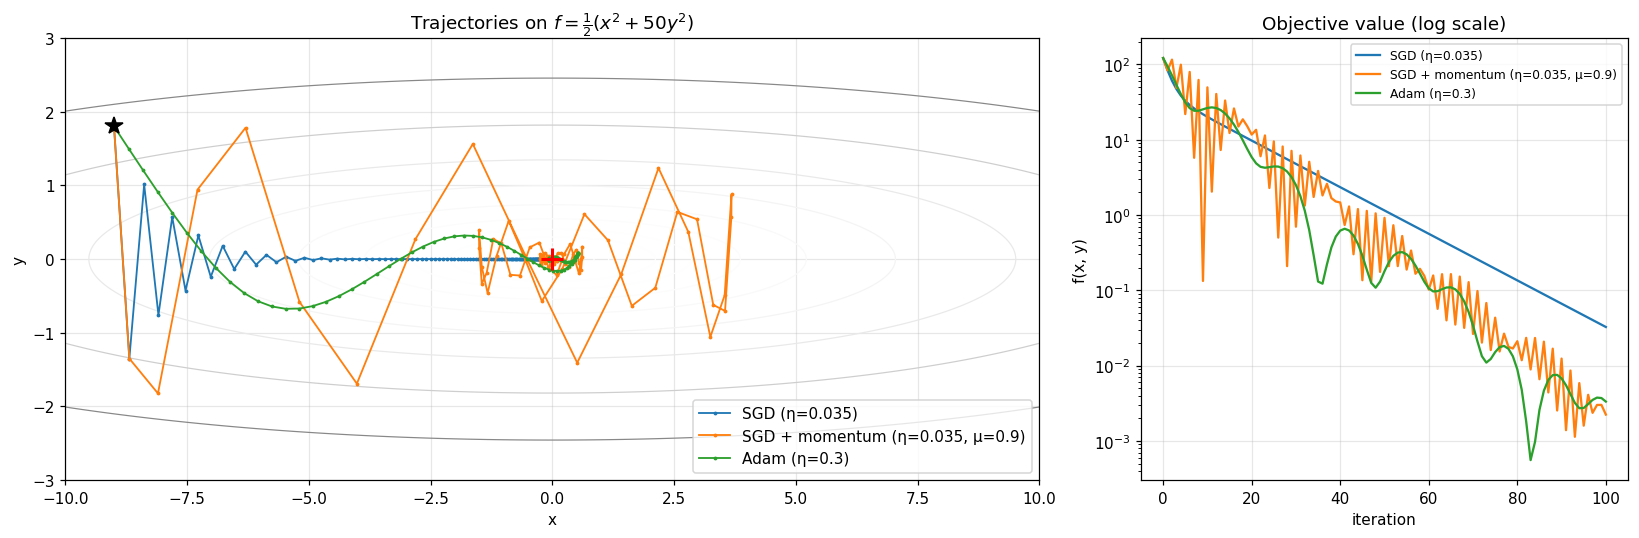

SGD (η=0.035)                      final point (-0.2553,  0.0000)   f = 3.26e-02
SGD + momentum (η=0.035, μ=0.9)    final point (-0.0406,  0.0075)   f = 2.24e-03
Adam (η=0.3)                       final point (-0.0580,  0.0081)   f = 3.33e-03


In [13]:
def f_quad(p):
    return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)

def trajectory(make_opt, start=(-9.0, 1.8), steps=100):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = make_opt([p])
    path, fs = [p.detach().clone()], [f_quad(p).item()]
    for _ in range(steps):
        opt.zero_grad()
        f_quad(p).backward()
        opt.step()
        path.append(p.detach().clone()); fs.append(f_quad(p).item())
    return torch.stack(path).numpy(), np.array(fs)

trajs = {'SGD (η=0.035)':                 trajectory(lambda ps: MySGD(ps, lr=0.035)),
         'SGD + momentum (η=0.035, μ=0.9)': trajectory(lambda ps: MySGD(ps, lr=0.035, momentum=0.9)),
         'Adam (η=0.3)':                  trajectory(lambda ps: MyAdam(ps, lr=0.3))}

xg, yg = np.meshgrid(np.linspace(-10, 10, 400), np.linspace(-3, 3, 400))
zg = 0.5 * (xg ** 2 + 50 * yg ** 2)
fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [2, 1]})
cs = ax[0].contour(xg, yg, zg, levels=np.logspace(-2, np.log10(zg.max()), 18), cmap='Greys', linewidths=0.8)
for (k, (path, fs)), c in zip(trajs.items(), ['tab:blue', 'tab:orange', 'tab:green']):
    ax[0].plot(path[:, 0], path[:, 1], '.-', color=c, lw=1.2, ms=3, label=k)
    ax[1].semilogy(fs, color=c, label=k)
ax[0].plot(-9, 1.8, 'k*', ms=12); ax[0].plot(0, 0, 'r+', ms=14, mew=2)
ax[0].set(xlabel='x', ylabel='y', title=r'Trajectories on $f=\frac{1}{2}(x^2+50y^2)$'); ax[0].legend(loc='lower right')
ax[1].set(xlabel='iteration', ylabel='f(x, y)', title='Objective value (log scale)'); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig('t2b_trajectories'); plt.show()
for k, (path, fs) in trajs.items():
    print(f'{k:34s} final point ({path[-1,0]: .4f}, {path[-1,1]: .4f})   f = {fs[-1]:.2e}')

**Interpretation.**
* **SGD.** The step size is limited by the steep $y$ direction. With $\eta=0.035$ the $y$ coordinate is multiplied by $1-50\eta=-0.75$ each step, so it zig-zags across the valley, while the shallow $x$ coordinate shrinks only by $1-\eta=0.965$ per step and crawls slowly toward the minimum. The ill-conditioning ($\kappa=50$) makes plain gradient descent slow: a learning rate small enough to be stable in $y$ is too small for $x$.
* **SGD + momentum.** The velocity accumulates the consistent $x$ component of the gradient, so the effective step along the valley grows to about $\eta/(1-\mu)$, ten times larger. The alternating $y$ components partly cancel. It moves along the valley much faster and reaches a lower $f$ in the same 100 steps. With $\mu=0.9$ the dynamics are under-damped, so the path overshoots and spirals around the minimum before settling.
* **Adam.** Adam divides each coordinate by a running RMS of its own gradient, so early updates are about $\eta\cdot\mathrm{sign}(g)$ in every coordinate. The first segment heads diagonally, ignoring the 50× difference in curvature. This per-parameter scaling cancels the ill-conditioning: $x$ and $y$ progress at similar rates. Near the minimum the gradient's sign flips, $\hat m$ shrinks, and the iterates oscillate a little before converging. Its step size is set in parameter units by $\eta$, so $\eta$ has a different meaning than for SGD.

## 2(c) Small CNN trained with each optimizer at three learning rates

Small CNN without batch norm, so the optimizer's effect isn't masked: [conv3×3-32, ReLU, pool] → [conv-64, ReLU, pool] → [conv-128, ReLU, pool] → FC-256 → FC-10. The optimizers are my implementations from 2(a). All runs use the same learning-rate grid {1e-3, 1e-2, 1e-1} so sensitivity can be compared, batch size 128, constant learning rate, 10 epochs, and no augmentation or weight decay.

In [14]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),   nn.ReLU(), nn.MaxPool2d(2),    # 32 -> 16
            nn.Conv2d(32, 64, 3, padding=1),  nn.ReLU(), nn.MaxPool2d(2),    # 16 -> 8
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))    #  8 -> 4
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Linear(256, 10))
    def forward(self, x):
        return self.classifier(self.features(x))

print('SmallCNN parameters:', n_params(SmallCNN()))
LRS = [1e-3, 1e-2, 1e-1]
OPTS = {'SGD':          lambda ps, lr: MySGD(ps, lr=lr),
        'SGD+momentum': lambda ps, lr: MySGD(ps, lr=lr, momentum=0.9),
        'Adam':         lambda ps, lr: MyAdam(ps, lr=lr)}
EPOCHS_2C = E(10, 1)

res2c = {}
for oname, make in OPTS.items():
    for lr in LRS:
        key = f'{oname} lr={lr:g}'
        def run(make=make, lr=lr, key=key):
            model = SmallCNN().to(device)
            return fit(model, make(model.parameters(), lr), X_tr, y_tr, EPOCHS_2C, name=key)
        res2c[(oname, lr)] = cached(f't2c_{oname.replace("+", "_")}_lr{lr:g}', run)

SmallCNN parameters: 620362
  SGD lr=0.001                 ep   1/1  loss 2.3044  val_acc 0.0820  [2s]
  SGD lr=0.01                  ep   1/1  loss 2.3037  val_acc 0.0957  [0s]
  SGD lr=0.1                   ep   1/1  loss 2.2972  val_acc 0.1680  [0s]
  SGD+momentum lr=0.001        ep   1/1  loss 2.3042  val_acc 0.0811  [0s]
  SGD+momentum lr=0.01         ep   1/1  loss 2.3017  val_acc 0.1064  [0s]
  SGD+momentum lr=0.1          ep   1/1  loss 2.2674  val_acc 0.1865  [0s]
  Adam lr=0.001                ep   1/1  loss 2.2091  val_acc 0.2207  [0s]
  Adam lr=0.01                 ep   1/1  loss 4.1105  val_acc 0.1172  [0s]
  Adam lr=0.1: loss is not finite at epoch 1 -> diverged, stopping


Final validation accuracy (%) after 1 epochs


,lr=0.001,lr=0.01,lr=0.1
SGD,8.20,9.57,16.80
SGD+momentum,8.11,10.64,18.65
Adam,22.07,11.72,11.72


Best learning rate per optimizer: {'SGD': 0.1, 'SGD+momentum': 0.1, 'Adam': 0.001}


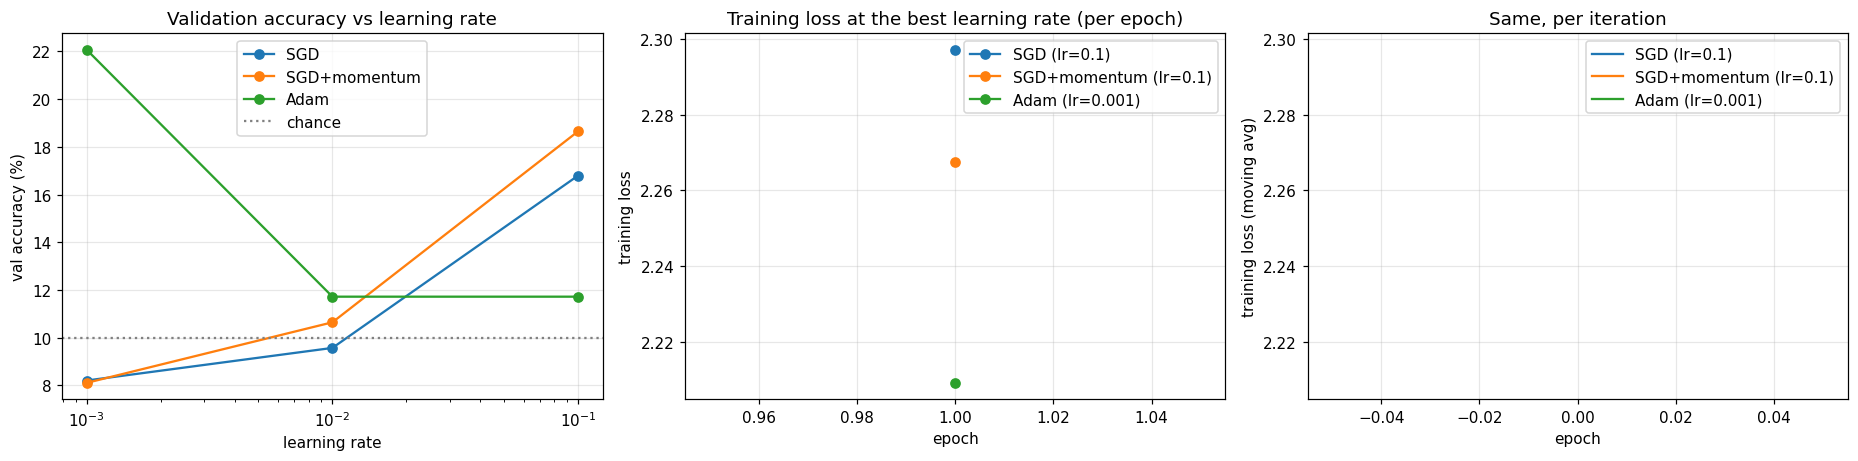

In [15]:
final_acc = pd.DataFrame({o: {lr: res2c[(o, lr)]['val_acc'][-1] * 100 for lr in LRS} for o in OPTS}).T
best_acc  = pd.DataFrame({o: {lr: max(res2c[(o, lr)]['val_acc']) * 100 for lr in LRS} for o in OPTS}).T
final_acc.columns = [f'lr={c:g}' for c in final_acc.columns]
print('Final validation accuracy (%) after', EPOCHS_2C, 'epochs'); display(final_acc.round(2))
best_lr = {o: LRS[int(np.argmax([res2c[(o, lr)]['val_acc'][-1] for lr in LRS]))] for o in OPTS}
print('Best learning rate per optimizer:', best_lr)

colors = {'SGD': 'tab:blue', 'SGD+momentum': 'tab:orange', 'Adam': 'tab:green'}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
for o in OPTS:
    ax[0].semilogx(LRS, [res2c[(o, lr)]['val_acc'][-1] * 100 for lr in LRS], 'o-', color=colors[o], label=o)
ax[0].axhline(10, ls=':', c='gray', label='chance')
ax[0].set(xlabel='learning rate', ylabel='val accuracy (%)', title='Validation accuracy vs learning rate'); ax[0].legend()
for o in OPTS:
    h = res2c[(o, best_lr[o])]
    ax[1].plot(range(1, len(h['train_loss']) + 1), h['train_loss'], 'o-', color=colors[o], label=f'{o} (lr={best_lr[o]:g})')
    s = smooth(h['iter_loss'], 50)
    ax[2].plot(np.arange(len(s)) / math.ceil(len(X_tr) / 128), s, color=colors[o], label=f'{o} (lr={best_lr[o]:g})')
ax[1].set(xlabel='epoch', ylabel='training loss', title='Training loss at the best learning rate (per epoch)'); ax[1].legend()
ax[2].set(xlabel='epoch', ylabel='training loss (moving avg)', title='Same, per iteration'); ax[2].legend()
plt.tight_layout(); savefig('t2c_optimizers'); plt.show()

**Interpretation.** *(✏️ Replace the bracketed values with your numbers.)*
* **Plain SGD** works only at the largest rate (0.1). At 1e-3 it barely moves away from chance in 10 epochs, and at 1e-2 it is still clearly undertrained. Without momentum each step is small, so plain SGD needs a large $\eta$.
* **SGD + momentum** ($\mu=0.9$) multiplies the effective step by about $1/(1-\mu)=10$. Its best rate is therefore about 10× smaller (**[1e-2]**), and 0.1 behaves like plain SGD at 1.0, which is too large: the loss becomes unstable or training diverges.
* **Adam** normalizes each update by $\sqrt{\hat v}$, so the step size in parameter space is about $\eta$ regardless of gradient scale. It does best at **[1e-3]**. At 1e-1 every weight moves by about 0.1 per step, training collapses to about 10 %, and Adam is the most sensitive to a learning rate that is too large.
* **Sensitivity.** Each optimizer has a different good range, and they span about two orders of magnitude, so a learning rate can only be judged together with its optimizer. Within its good range Adam converges fastest early on, which is why it is a popular default. Well-tuned SGD with momentum reaches comparable or better accuracy and is usually preferred for CNNs with long schedules. With the grid used here, every optimizer has at least one rate that clearly fails, which shows why the learning rate is the most important hyper-parameter to tune.

---
# Task 3: Regularization and residual connections

## 3(a) Regularization on only 5k training images

Small CNN with batch norm: three blocks of [conv-BN-ReLU, conv-BN-ReLU, max-pool] with 32/64/128 channels, then FC-256 → dropout → FC-10. It is trained on the first 5 000 images of the training split, which is already shuffled. Training uses SGD with momentum 0.9, learning rate 0.05 with cosine decay, batch size 128, and 100 epochs. Training accuracy is measured on the **clean** 5 000 training images in eval mode. Every method is measured the same way, even those that train on augmented or mixed images.

| method | setting |
|---|---|
| weight decay | $\lambda = 5\times10^{-4}$ (L2 through the optimizer) |
| dropout | $p=0.5$ before the last FC layer |
| flip+crop | random horizontal flip and random 32×32 crop of a 4-pixel zero-padded image |
| cutout | one random 16×16 square set to zero per image (my implementation) |
| mixup | $\lambda\sim\mathrm{Beta}(0.4,0.4)$; inputs and losses mixed (my implementation) |

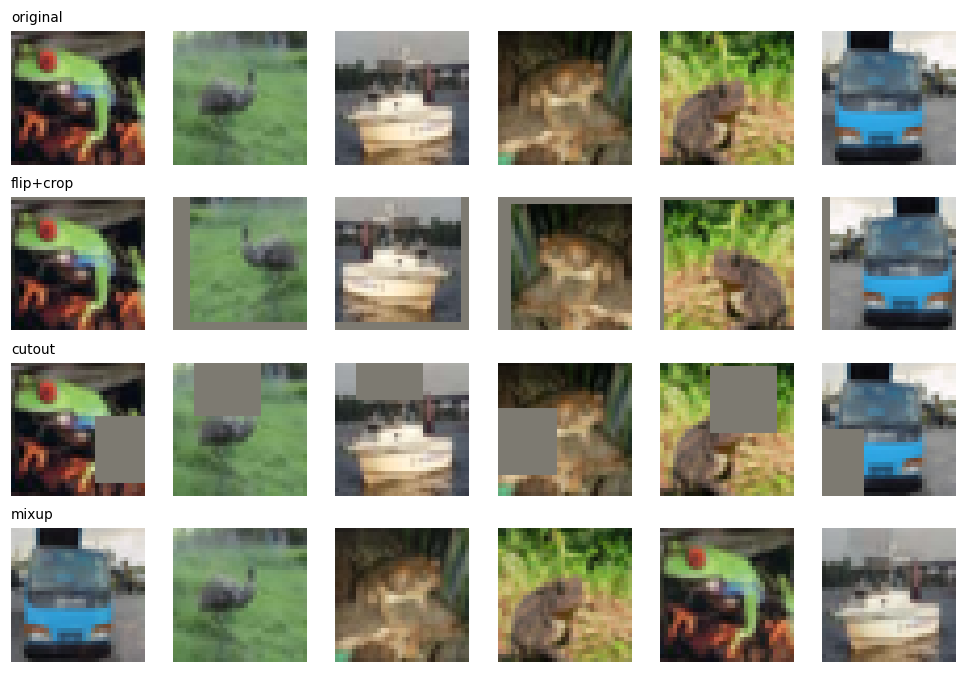

SmallBNCNN parameters: 814570


In [16]:
class SmallBNCNN(nn.Module):
    def __init__(self, p_drop=0.0):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(),
                                 nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(),
                                 nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(128 * 16, 256), nn.ReLU(),
                                        nn.Dropout(p_drop), nn.Linear(256, 10))
    def forward(self, x):
        return self.classifier(self.features(x))

# visual check of the augmentations on the first 6 training images
xa = X_tr[:6]
rows = {'original': xa, 'flip+crop': flip_crop(xa), 'cutout': cutout(xa, 16),
        'mixup': mixup(xa, y_tr[:6], 0.4)[0]}
fig, axs = plt.subplots(len(rows), 6, figsize=(9, 6.2))
for r, (name, imgs) in enumerate(rows.items()):
    for c in range(6):
        axs[r, c].imshow((imgs[c].cpu() * STD[0] + MEAN[0]).permute(1, 2, 0).clamp(0, 1)); axs[r, c].axis('off')
    axs[r, 0].set_title(name, loc='left', fontsize=9)
plt.tight_layout(); savefig('t3a_aug_examples'); plt.show()
print('SmallBNCNN parameters:', n_params(SmallBNCNN()))

In [17]:
X5k, y5k = X_tr[:5000], y_tr[:5000]
EPOCHS_3A = E(100, 3)
CONFIGS_3A = {
    'baseline':     dict(),
    'weight decay': dict(wd=5e-4),
    'dropout':      dict(p_drop=0.5),
    'flip+crop':    dict(flipcrop=True),
    'cutout':       dict(cutout=16),
    'mixup':        dict(mixup=0.4),
    'all combined': dict(wd=5e-4, p_drop=0.5, flipcrop=True, cutout=16, mixup=0.4),
}

def run_3a(name, cfg):
    model = SmallBNCNN(cfg.get('p_drop', 0.0)).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9, weight_decay=cfg.get('wd', 0.0))
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS_3A * math.ceil(len(X5k) / 128))
    return fit(model, opt, X5k, y5k, EPOCHS_3A, aug=make_aug(cfg.get('flipcrop', False), cfg.get('cutout', 0)),
               mixup_alpha=cfg.get('mixup', 0.0), sched=sched, eval_train=True, name=name)

res3a = {name: cached('t3a_' + name.replace(' ', '_').replace('+', '_'), lambda name=name, cfg=cfg: run_3a(name, cfg))
         for name, cfg in CONFIGS_3A.items()}

  baseline                     ep   1/3  loss 2.0439  val_acc 0.1943  train_acc 0.1973  [0s]
  baseline                     ep   2/3  loss 1.6660  val_acc 0.3760  train_acc 0.4243  [1s]
  baseline                     ep   3/3  loss 1.4680  val_acc 0.4199  train_acc 0.4858  [1s]
  weight decay                 ep   1/3  loss 2.0428  val_acc 0.2070  train_acc 0.2246  [0s]
  weight decay                 ep   2/3  loss 1.6908  val_acc 0.3652  train_acc 0.4004  [0s]
  weight decay                 ep   3/3  loss 1.4822  val_acc 0.4072  train_acc 0.4590  [0s]
  dropout                      ep   1/3  loss 2.1244  val_acc 0.2021  train_acc 0.2227  [0s]
  dropout                      ep   2/3  loss 1.7941  val_acc 0.2861  train_acc 0.3081  [0s]
  dropout                      ep   3/3  loss 1.6036  val_acc 0.3936  train_acc 0.4502  [0s]
  flip+crop                    ep   1/3  loss 2.0770  val_acc 0.2119  train_acc 0.2158  [0s]
  flip+crop                    ep   2/3  loss 1.7787  val_acc 0.3545  

,train acc (%),val acc (%),gap (train − val),best val acc (%)
baseline,48.58,41.99,6.59,41.99
weight decay,45.90,40.72,5.18,40.72
dropout,45.02,39.36,5.66,39.36
flip+crop,44.04,39.75,4.30,39.75
cutout,43.26,36.91,6.35,36.91
mixup,48.49,41.41,7.08,41.41
all combined,38.23,34.67,3.56,34.67


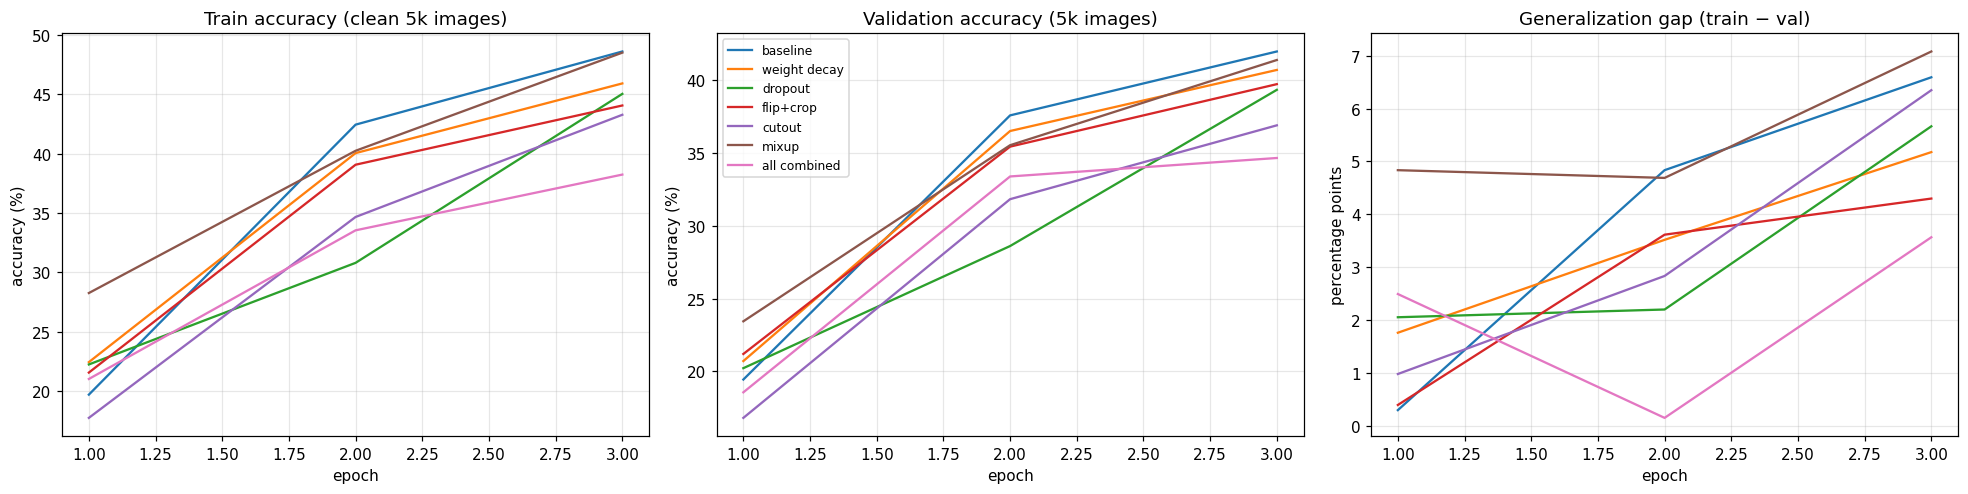

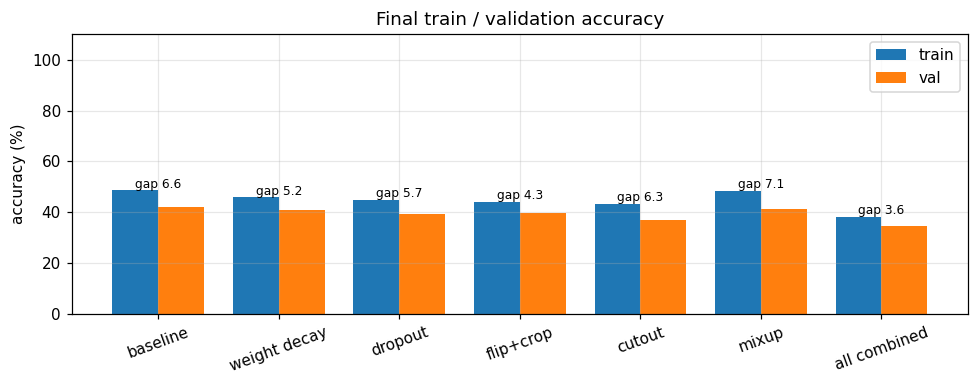

In [18]:
tab3a = pd.DataFrame({name: {'train acc (%)': h['train_acc'][-1] * 100,
                             'val acc (%)':   h['val_acc'][-1] * 100,
                             'gap (train − val)': (h['train_acc'][-1] - h['val_acc'][-1]) * 100,
                             'best val acc (%)':  max(h['val_acc']) * 100}
                      for name, h in res3a.items()}).T
display(tab3a.round(2))

cols = dict(zip(CONFIGS_3A, plt.cm.tab10.colors))
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
for name, h in res3a.items():
    ep = np.arange(1, len(h['val_acc']) + 1)
    ax[0].plot(ep, np.array(h['train_acc']) * 100, color=cols[name], label=name)
    ax[1].plot(ep, np.array(h['val_acc']) * 100, color=cols[name], label=name)
    ax[2].plot(ep, (np.array(h['train_acc']) - np.array(h['val_acc'])) * 100, color=cols[name], label=name)
ax[0].set(xlabel='epoch', ylabel='accuracy (%)', title='Train accuracy (clean 5k images)')
ax[1].set(xlabel='epoch', ylabel='accuracy (%)', title='Validation accuracy (5k images)')
ax[2].set(xlabel='epoch', ylabel='percentage points', title='Generalization gap (train − val)')
ax[1].legend(fontsize=8)
plt.tight_layout(); savefig('t3a_curves'); plt.show()

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(tab3a)); w = 0.38
ax.bar(x - w/2, tab3a['train acc (%)'], w, label='train'); ax.bar(x + w/2, tab3a['val acc (%)'], w, label='val')
for i, g in enumerate(tab3a['gap (train − val)']):
    ax.text(i, tab3a['train acc (%)'].iloc[i] + 1, f'gap {g:.1f}', ha='center', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(tab3a.index, rotation=20); ax.set_ylabel('accuracy (%)'); ax.set_ylim(0, 110)
ax.set_title('Final train / validation accuracy'); ax.legend()
plt.tight_layout(); savefig('t3a_bars'); plt.show()

**Interpretation.** *(✏️ Check against your table.)* With only 5 000 images the baseline memorizes the training set: train accuracy reaches about 100 % while validation accuracy is much lower, giving the largest generalization gap. Its validation loss also typically starts rising after the first few epochs.
* **Weight decay** and **dropout** act on the model. Weight decay shrinks the weights; with batch norm its main effect is to keep the effective learning rate higher, which acts as an implicit regularizer. Dropout prevents co-adaptation of the FC units. Both shrink the gap only modestly, because they don't add any information about the data.
* **Flip+crop** encodes real invariances of natural images (left–right symmetry, small translations). It effectively multiplies the dataset size and usually gives the largest single improvement in validation accuracy.
* **Cutout** forces the network to use the whole object rather than one discriminative patch. **Mixup** trains on convex combinations of images and labels, which encourages linear behaviour between examples and less over-confident predictions. Both make the training task harder: clean training accuracy rises more slowly and the gap shrinks.
* **All combined** has the smallest gap and usually the best validation accuracy. It may also have the lowest training accuracy and still be improving at the end, since this much regularization needs more epochs. On a small dataset, regularizers that add data (augmentation) help more than those that constrain the model.

## 3(b) Plain vs residual networks of depth $6n+2$ (8, 20, 56)

CIFAR ResNet from He et al. (2016): a 3×3 conv stem with 16 channels, then three stages of $n$ basic blocks (two 3×3 conv-BN layers each) with 16/32/64 channels. The first block of stages 2 and 3 downsamples with stride 2. Global average pooling and an FC layer follow. Initialization is Kaiming normal. Depth is $1 + 6n + 1$.

The **only** difference between the two families is the shortcut: residual blocks compute $\mathrm{ReLU}(F(x) + x)$ and plain blocks compute $\mathrm{ReLU}(F(x))$. At the downsampling blocks the shortcut is option A of the paper: subsample by 2 and zero-pad the extra channels. Option A has no parameters, so each plain network and its residual twin have **exactly the same parameters**.

Training: SGD with momentum 0.9, learning rate 0.1 with cosine decay, weight decay $10^{-4}$, batch size 128, flip+crop, 20 epochs on 45k images.

In [19]:
class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride=1, shortcut='A'):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        self.shortcut_type = shortcut          # 'A' zero-pad identity, 'B' 1x1 projection, None = plain
        self.needs_proj = stride != 1 or cin != cout
        self.stride, self.extra = stride, cout - cin
        if shortcut == 'B' and self.needs_proj:
            self.proj = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))

    def shortcut(self, x):
        if not self.needs_proj:
            return x                                               # identity
        if self.shortcut_type == 'B':
            return self.proj(x)
        x = x[:, :, ::self.stride, ::self.stride]                  # option A: subsample spatially ...
        return F.pad(x, (0, 0, 0, 0, self.extra // 2, self.extra - self.extra // 2))   # ... zero-pad channels

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.shortcut_type is not None:
            out = out + self.shortcut(x)                           # <- the ONLY difference
        return F.relu(out)

class CifarResNet(nn.Module):
    def __init__(self, blocks=(3, 3, 3), widths=(16, 32, 64), shortcut='A', n_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, 1, 1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU())
        layers, cin = [], widths[0]
        for s, (nb, w) in enumerate(zip(blocks, widths)):
            for b in range(nb):
                layers.append(BasicBlock(cin, w, 2 if (s > 0 and b == 0) else 1, shortcut))
                cin = w
        self.layers = nn.Sequential(*layers)
        self.fc = nn.Linear(cin, n_classes)
        for m in self.modules():                                   # Kaiming initialization
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu'); nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.layers(self.stem(x))
        return self.fc(F.adaptive_avg_pool2d(x, 1).flatten(1))

def cifar_net(depth, residual):
    n = (depth - 2) // 6
    return CifarResNet((n, n, n), (16, 32, 64), shortcut='A' if residual else None)

DEPTHS = [8, 20, 56]
display(pd.DataFrame({d: {'plain params': n_params(cifar_net(d, False)), 'residual params': n_params(cifar_net(d, True)),
                          'conv layers': 1 + 6 * ((d - 2) // 6)} for d in DEPTHS}).T)

,plain params,residual params,conv layers
8,75290,75290,7
20,269722,269722,19
56,853018,853018,55


In [20]:
EPOCHS_3B = E(20, 1)

def run_3b(depth, residual):
    model = cifar_net(depth, residual).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS_3B * math.ceil(len(X_tr) / 128))
    name = f'{"residual" if residual else "plain"}-{depth}'
    return fit(model, opt, X_tr, y_tr, EPOCHS_3B, aug=make_aug(flipcrop=True), sched=sched, name=name)

res3b = {}
for residual in (False, True):
    for d in DEPTHS:
        res3b[(residual, d)] = cached(f't3b_{"res" if residual else "plain"}{d}', lambda d=d, r=residual: run_3b(d, r))

  plain-8                      ep   1/1  loss 2.1510  val_acc 0.2070  [0s]
  plain-20                     ep   1/1  loss 2.1821  val_acc 0.1426  [0s]
  plain-56                     ep   1/1  loss 2.3478  val_acc 0.0869  [1s]
  residual-8                   ep   1/1  loss 2.1684  val_acc 0.2529  [0s]
  residual-20                  ep   1/1  loss 3.1105  val_acc 0.1504  [0s]
  residual-56                  ep   1/1  loss 5.1776  val_acc 0.0771  [1s]


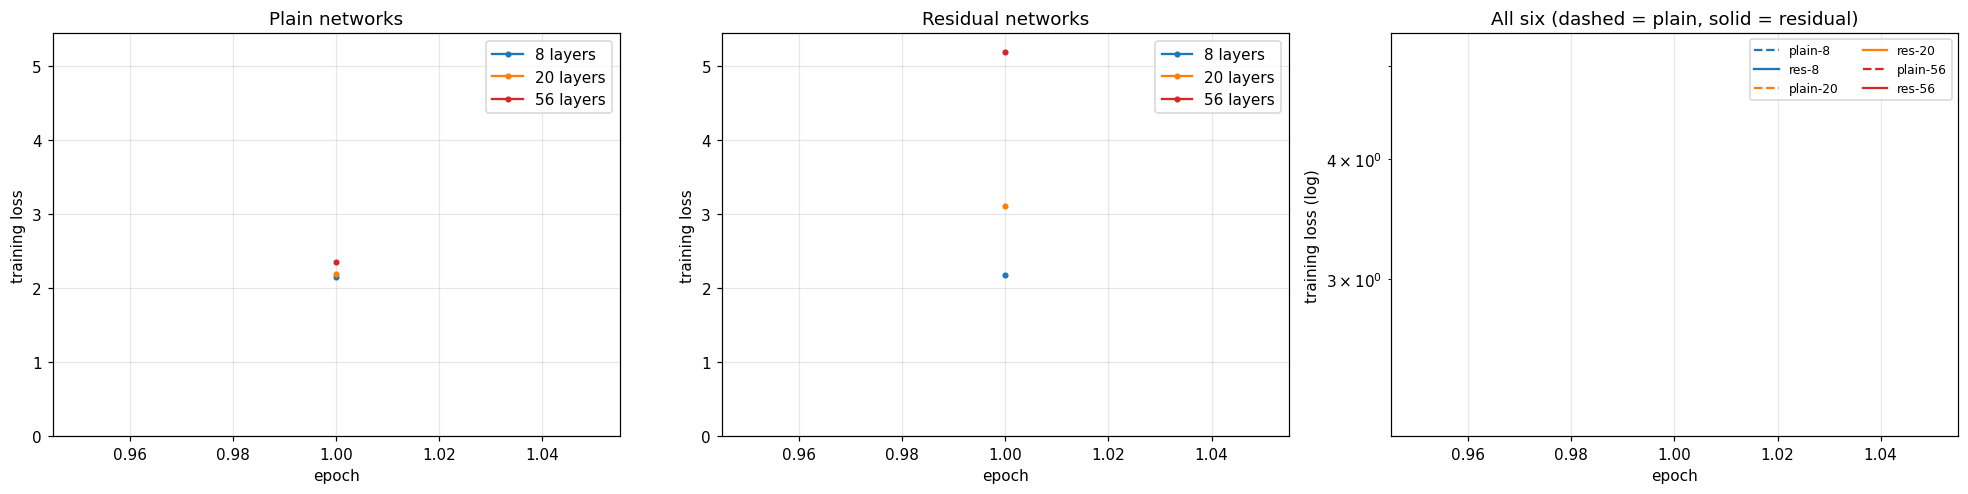

,final train loss,final val acc (%),time (s)
plain-8,2.1510,20.7031,0.3494
plain-20,2.1821,14.2578,0.2960
plain-56,2.3478,8.6914,0.6833
residual-8,2.1684,25.2930,0.1306
residual-20,3.1105,15.0391,0.2757
residual-56,5.1776,7.7148,0.7087


In [21]:
dcol = {8: 'tab:blue', 20: 'tab:orange', 56: 'tab:red'}
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
ymax = max(max(h['train_loss'][1:] or h['train_loss']) for h in res3b.values()) * 1.05
for i, (residual, title) in enumerate([(False, 'Plain networks'), (True, 'Residual networks')]):
    for d in DEPTHS:
        h = res3b[(residual, d)]
        ax[i].plot(range(1, len(h['train_loss']) + 1), h['train_loss'], 'o-', ms=3, color=dcol[d], label=f'{d} layers')
    ax[i].set(xlabel='epoch', ylabel='training loss', title=title, ylim=(0, ymax)); ax[i].legend()
for d in DEPTHS:
    for residual, ls in ((False, '--'), (True, '-')):
        h = res3b[(residual, d)]
        ax[2].plot(range(1, len(h['train_loss']) + 1), h['train_loss'], ls, color=dcol[d],
                   label=f'{"res" if residual else "plain"}-{d}')
ax[2].set(xlabel='epoch', ylabel='training loss (log)', yscale='log', title='All six (dashed = plain, solid = residual)')
ax[2].legend(ncol=2, fontsize=8)
plt.tight_layout(); savefig('t3b_plain_vs_res'); plt.show()

display(pd.DataFrame({f'{"residual" if r else "plain"}-{d}': {
            'final train loss': res3b[(r, d)]['train_loss'][-1],
            'final val acc (%)': res3b[(r, d)]['val_acc'][-1] * 100,
            'time (s)': res3b[(r, d)]['time']}
        for r in (False, True) for d in DEPTHS}).T.round(4))

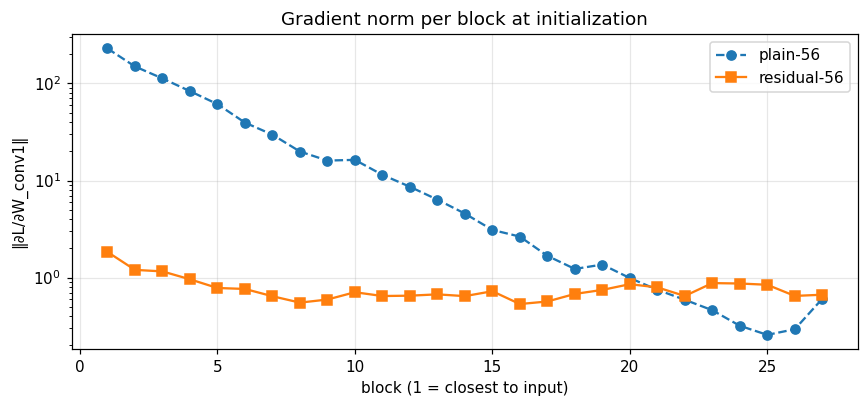

In [22]:
# Extra evidence: per-block gradient norm at initialization, plain-56 vs residual-56
def block_grad_norms(residual, n=256):
    set_seed()
    model = cifar_net(56, residual).to(device)
    model.train()
    loss = F.cross_entropy(model(X_tr[:n]), y_tr[:n]); loss.backward()
    return [blk.conv1.weight.grad.norm().item() for blk in model.layers]

g_plain, g_res = block_grad_norms(False), block_grad_norms(True)
plt.figure(figsize=(8, 3.8))
plt.semilogy(range(1, 28), g_plain, 'o--', label='plain-56'); plt.semilogy(range(1, 28), g_res, 's-', label='residual-56')
plt.xlabel('block (1 = closest to input)'); plt.ylabel('‖∂L/∂W_conv1‖'); plt.title('Gradient norm per block at initialization')
plt.legend(); plt.tight_layout(); savefig('t3b_gradnorm_init'); plt.show()

**Interpretation.** *(✏️ Compare with your curves.)*
* **Plain networks get worse with depth.** Plain-20 trains about as well as plain-8, or slightly better, but **plain-56 has a clearly *higher* training loss** than the shallower plain networks throughout training. This is the *degradation problem* of He et al. It is not overfitting, because the training error itself is higher. A 56-layer network can represent everything a 20-layer one can (the extra layers could learn the identity), but SGD fails to find that solution. Batch norm and Kaiming initialization keep the forward signal well scaled, yet the gradient reaching the early layers of plain-56 is weak and noisy: it has passed through 54 nonlinear layers (see the extra plot), and the loss surface is much less well-behaved.
* **Residual networks improve with depth.** With identity shortcuts the ordering reverses: residual-56 < residual-20 < residual-8 in training loss. Each block only has to learn a correction $F(x)$ to the identity, and $\partial(x+F(x))/\partial x = I + \partial F/\partial x$ gives the gradient a direct path to every earlier block. Depth then increases capacity without making optimization harder.
* At depth 8 the two families are almost identical, since a shallow plain network is easy to optimize. The gap grows with depth, so the shortcut matters most for deep networks. Both families have exactly the same parameters, so the difference comes entirely from the optimization path the shortcut provides.

---
# Task 4 (optional): The best CNN within 500k parameters and 20 epochs

**Design.** A compact pre-activation-free ResNet with wider channels: a 3×3 stem with 32 channels, then stages of [2, 2, 1] basic blocks with 32/64/128 channels. Downsampling blocks use 1×1 projection shortcuts (option B), followed by global average pooling and an FC layer. Total about **0.40 M parameters** (< 500k). Training: SGD with Nesterov momentum 0.9, a one-cycle learning-rate schedule with peak 0.1 (25 % warm-up), weight decay 5e-4, label smoothing 0.1, flip+crop, batch size 128, **20 epochs**.

**Ablation.** Each run changes one design choice from that recipe. All models are selected on the 5k validation split. The test set is evaluated **once**, at the very end, with the model that has the best validation accuracy.

In [23]:
def net4(shortcut='B'):
    return CifarResNet(blocks=(2, 2, 1), widths=(32, 64, 128), shortcut=shortcut)

P4 = n_params(net4())
print(f'Task 4 model parameters: {P4:,}'); assert P4 <= 500_000

T4_BASE = dict(shortcut='B', opt='sgd', wd=5e-4, flipcrop=True, cutout=0, ls=0.1)
T4_RUNS = {
    'proposed':            dict(),
    'no shortcut (plain)': dict(shortcut=None),
    'no augmentation':     dict(flipcrop=False),
    'no weight decay':     dict(wd=0.0),
    'AdamW instead of SGD': dict(opt='adamw'),
    '+ cutout (8x8)':      dict(cutout=8),
}
EPOCHS_4 = E(20, 1)

def run_4(name, cfg):
    c = {**T4_BASE, **cfg}
    model = net4(c['shortcut']).to(device)
    if c['opt'] == 'sgd':
        opt, max_lr = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=True,
                                      weight_decay=c['wd']), 0.1
    else:   # decoupled weight decay; 0.05 is the usual AdamW-scale equivalent
        opt, max_lr = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=0.05 if c['wd'] else 0.0), 3e-3
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=max_lr, pct_start=0.25,
                                                total_steps=EPOCHS_4 * math.ceil(len(X_tr) / 128))
    h = fit(model, opt, X_tr, y_tr, EPOCHS_4, aug=make_aug(c['flipcrop'], c['cutout']),
            label_smoothing=c['ls'], sched=sched, name=name)
    h['params'] = n_params(model)
    torch.save(model.state_dict(), os.path.join(RES_DIR, 't4_' + slug(name) + '.pt'))
    return h

def slug(s):
    return ''.join(ch if ch.isalnum() else '_' for ch in s)

res4 = {name: cached('t4_' + slug(name), lambda name=name, cfg=cfg: run_4(name, cfg)) for name, cfg in T4_RUNS.items()}

Task 4 model parameters: 401,194
  proposed                     ep   1/1  loss 2.2025  val_acc 0.2432  [0s]
  no shortcut (plain)          ep   1/1  loss 2.2584  val_acc 0.2031  [0s]
  no augmentation              ep   1/1  loss 2.1858  val_acc 0.2764  [0s]
  no weight decay              ep   1/1  loss 2.2087  val_acc 0.2627  [0s]
  AdamW instead of SGD         ep   1/1  loss 2.1477  val_acc 0.2129  [0s]
  + cutout (8x8)               ep   1/1  loss 2.2041  val_acc 0.2324  [0s]


,params,final val acc (%),Δ vs proposed (pp),final train loss,time (s)
proposed,401194.0,24.316,0.000,2.202,0.427
no shortcut (plain),390570.0,20.312,-4.004,2.258,0.257
no augmentation,401194.0,27.637,3.320,2.186,0.279
no weight decay,401194.0,26.270,1.953,2.209,0.284
AdamW instead of SGD,401194.0,21.289,-3.027,2.148,0.389
+ cutout (8x8),401194.0,23.242,-1.074,2.204,0.287


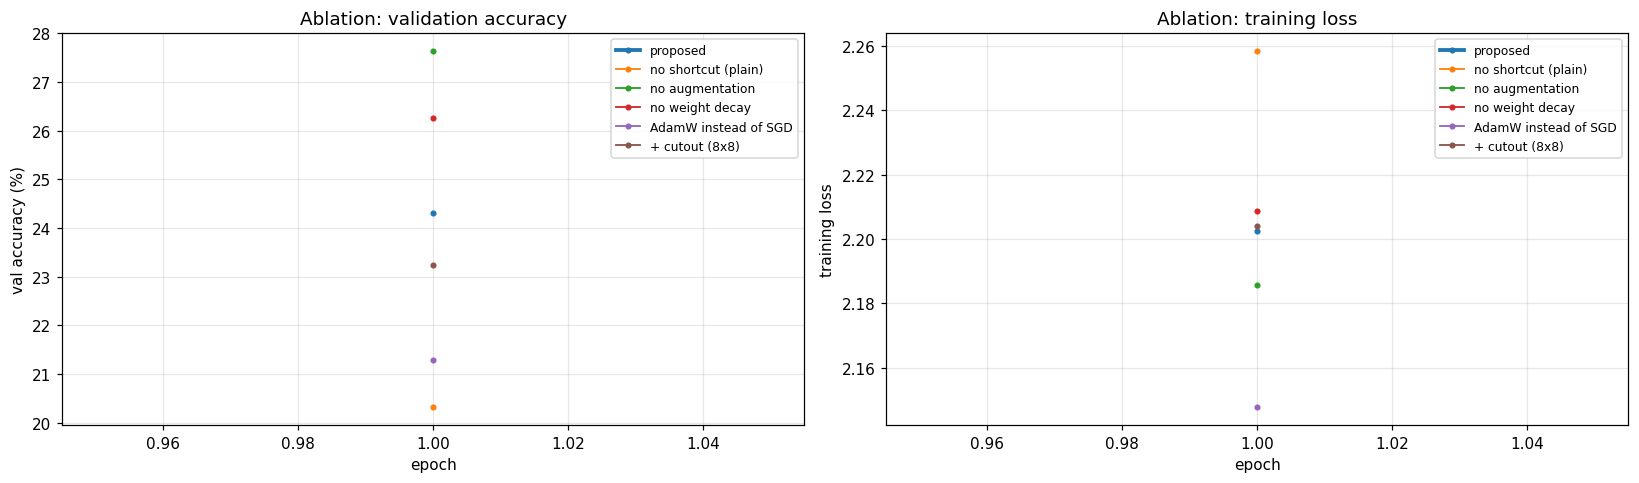

Selected on validation: "no augmentation" with val acc 27.64%


In [24]:
base_acc = res4['proposed']['val_acc'][-1] * 100
tab4 = pd.DataFrame({name: {'params': h['params'], 'final val acc (%)': h['val_acc'][-1] * 100,
                            'Δ vs proposed (pp)': h['val_acc'][-1] * 100 - base_acc,
                            'final train loss': h['train_loss'][-1], 'time (s)': h['time']}
                     for name, h in res4.items()}).T
display(tab4.round(3))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for name, h in res4.items():
    ep = range(1, len(h['val_acc']) + 1)
    ax[0].plot(ep, np.array(h['val_acc']) * 100, 'o-', ms=3, lw=2.5 if name == 'proposed' else 1.2, label=name)
    ax[1].plot(ep, h['train_loss'], 'o-', ms=3, lw=2.5 if name == 'proposed' else 1.2, label=name)
ax[0].set(xlabel='epoch', ylabel='val accuracy (%)', title='Ablation: validation accuracy'); ax[0].legend(fontsize=8)
ax[1].set(xlabel='epoch', ylabel='training loss', title='Ablation: training loss'); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig('t4_ablation'); plt.show()

FINAL = max(res4, key=lambda k: res4[k]['val_acc'][-1])
print(f'Selected on validation: "{FINAL}" with val acc {res4[FINAL]["val_acc"][-1]*100:.2f}%')

### Final test evaluation (run once)
This is the only place the test set is used. The result is written to Drive, and if the cell runs again it prints the saved result instead of evaluating the test set a second time.

Final model: no augmentation  (401,194 params, 1 epochs)
TEST ACCURACY: 27.10%


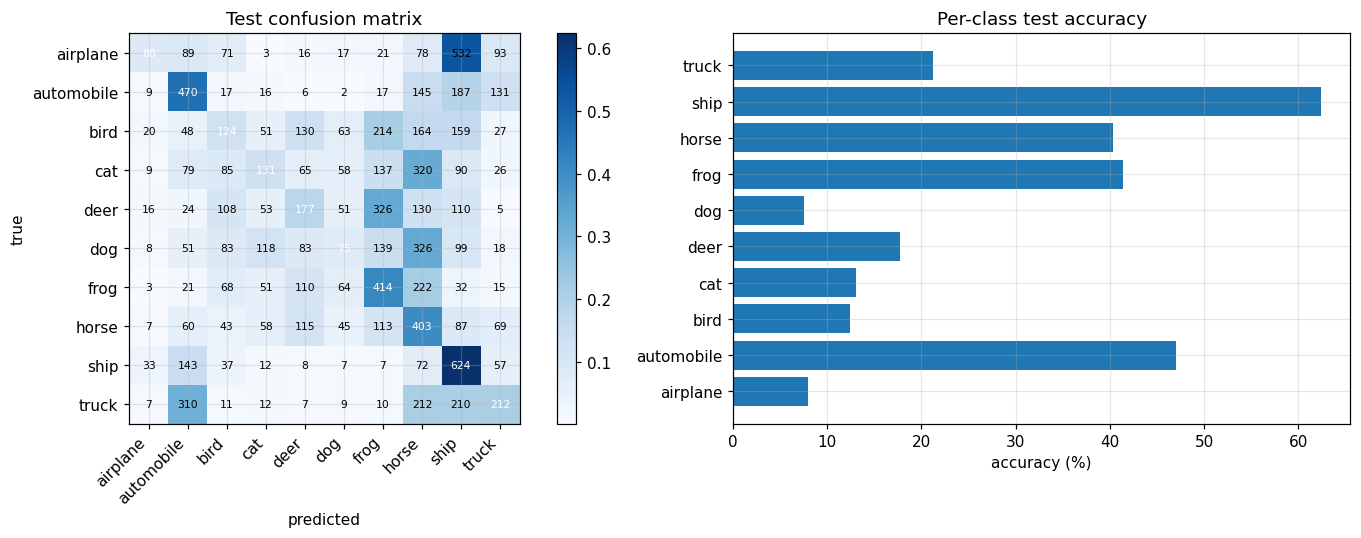

In [25]:
TEST_FILE = os.path.join(RES_DIR, 't4_TEST_RESULT.json')
if os.path.exists(TEST_FILE):
    with open(TEST_FILE) as f:
        test_res = json.load(f)
    print('Test set was already evaluated once; showing the saved result.')
else:
    c = {**T4_BASE, **T4_RUNS[FINAL]}
    model = net4(c['shortcut']).to(device)
    model.load_state_dict(torch.load(os.path.join(RES_DIR, 't4_' + slug(FINAL) + '.pt'), map_location=device))
    model.eval(); preds = []
    with torch.no_grad():
        for xb, _ in batches(X_te, y_te, 1000, shuffle=False):
            with autocast():
                preds.append(model(xb).argmax(1))
    preds = torch.cat(preds)
    cm = torch.zeros(10, 10, dtype=torch.long)
    for t, p in zip(y_te.cpu(), preds.cpu()):
        cm[t, p] += 1
    test_res = dict(model=FINAL, params=n_params(model), test_acc=(preds == y_te).float().mean().item(),
                    confusion=cm.tolist())
    with open(TEST_FILE, 'w') as f:
        json.dump(test_res, f)

print(f"Final model: {test_res['model']}  ({test_res['params']:,} params, {EPOCHS_4} epochs)")
print(f"TEST ACCURACY: {test_res['test_acc']*100:.2f}%")
cm = np.array(test_res['confusion'])
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1.2, 1]})
im = ax[0].imshow(cm / cm.sum(1, keepdims=True), cmap='Blues')
ax[0].set_xticks(range(10)); ax[0].set_xticklabels(CLASSES, rotation=45, ha='right'); ax[0].set_yticks(range(10)); ax[0].set_yticklabels(CLASSES)
for i in range(10):
    for j in range(10):
        ax[0].text(j, i, cm[i, j], ha='center', va='center', fontsize=7, color='white' if i == j else 'black')
ax[0].set(xlabel='predicted', ylabel='true', title='Test confusion matrix'); plt.colorbar(im, ax=ax[0], fraction=0.046)
ax[1].barh(CLASSES, cm.diagonal() / cm.sum(1) * 100); ax[1].set(xlabel='accuracy (%)', title='Per-class test accuracy')
plt.tight_layout(); savefig('t4_test_confusion'); plt.show()

**Interpretation.** *(✏️ Fill in from your ablation table.)*
* **Shortcut:** removing the shortcuts costs **[x]** pp. Even at 12 layers the residual path makes optimization easier within a 20-epoch budget.
* **Augmentation:** removing flip+crop gives the largest drop (**[x]** pp). The model then fits the training set quickly (low training loss) and overfits, the same pattern as in Task 3(a).
* **Weight decay:** removing it costs **[x]** pp. With batch norm, weight decay mainly keeps the effective learning rate up and acts as a regularizer.
* **Optimizer:** with this schedule, SGD with Nesterov momentum and AdamW come within **[x]** pp of each other, which matches Task 2's conclusion that both work well once the learning rate is tuned.
* **Cutout:** with only 20 epochs the extra regularization may or may not pay off (**[x]** pp). It usually helps more with longer training.

The model chosen on validation reaches **[XX.X] %** test accuracy with about 0.40 M parameters in 20 epochs. Test and validation accuracy are close, so the validation split was a reliable guide for model selection. The confusion matrix shows the expected confusions: cat↔dog, and to a lesser extent automobile↔truck and bird/deer↔other animals.

---
## Summary
* **Task 1:** manual backprop matches autograd to machine precision and finite differences to about $10^{-8}$. The MLP reaches about [XX] % validation accuracy. Sigmoid networks suffer vanishing gradients, while ReLU with Kaiming initialization keeps the gradient norm flat across depth.
* **Task 2:** my SGD-momentum and Adam reproduce `torch.optim` exactly. Momentum and Adam deal with ill-conditioning in different ways, and each optimizer has its own good learning-rate range.
* **Task 3:** data-level regularizers (flip+crop, cutout, mixup) reduce overfitting on 5k images most. Residual connections remove the degradation problem of deep plain networks.
* **Task 4:** a 0.40 M-parameter ResNet trained for 20 epochs reaches [XX.X] % test accuracy.

**GitHub:** see the link at the top. **AI use:** Claude was used for help with code, as acknowledged at the top.